# Segmentação de imagens

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import keras
from keras.layers import Rescaling, Conv2D, Conv2DTranspose
import tensorflow_datasets as tfds
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [53]:
!pip install importlib-resources

In [54]:
# 1. Carrega o dataset de pets sem travar na versão antiga
dataset_train, info = tfds.load(
    'oxford_iiit_pet',
    split='train[:80%]',
    with_info=True
)
dataset_val = tfds.load(
    'oxford_iiit_pet',
    split='train[80%:]'
)

# 2. Define a função de redimensionamento e normalização para imagem e máscara
def preprocess(datapoint):
    image = tf.image.resize(datapoint['image'], (128, 128))
    mask = tf.image.resize(datapoint['segmentation_mask'], (128, 128), method='nearest')

    # image = image / 255.0

    # Ajusta as classes da máscara para começarem em 0
    mask -= 1

    return image, mask

# 3. Aplica o pré-processamento no conjunto de treino
train_dataset = dataset_train.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_dataset = dataset_val.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

# 4. Configura lotes (batch) e otimização para treino
BATCH_SIZE = 32
BUFFER_SIZE = 1000

NUM_TRAIN_IMAGES = int(info.splits['train'].num_examples * 0.8)
STEPS_PER_EPOCH = NUM_TRAIN_IMAGES // BATCH_SIZE
img_size = (128, 128)

train_batches = (
    train_dataset
    .cache()
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

# 5. Configura lotes para a Validação (geralmente não precisa de shuffle nem repeat)
val_batches = (
    val_dataset
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

print("Dataset de segmentação carregado e estruturado com sucesso!")

Dataset de segmentação carregado e estruturado com sucesso!


In [55]:
train_dataset

<_ParallelMapDataset element_spec=(TensorSpec(shape=(128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(128, 128, 1), dtype=tf.uint8, name=None))>

In [56]:
num_train = info.splits['train'].num_examples
print(f"Número de imagens de treino: {num_train}")

Número de imagens de treino: 3680


In [57]:
info.features

FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})

In [58]:
# 1. Pega a quantidade total de classes
num_classes = 3

# 2. Se o dataset fornecer os nomes das classes/rótulos:
# (No caso do oxford_iiit_pet, as classes de segmentação costumam ser o fundo, o pet e o contorno)
print(f"Nomes das classes: {info.features['segmentation_mask']}")

Nomes das classes: Image(shape=(None, None, 1), dtype=uint8)


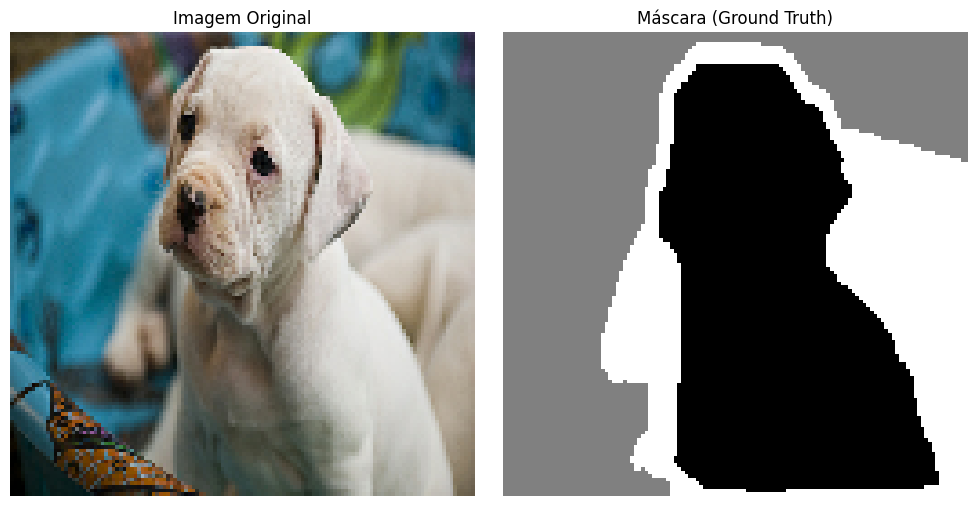

In [59]:
for images, mask in train_batches.take(1):
  img_exemplo = images[0].numpy()
  mask_exemplo = mask[0].numpy()

  plt.figure(figsize=(10, 5))

# Exibe a imagem original
plt.subplot(1, 2, 1)
plt.title("Imagem Original")
plt.imshow(img_exemplo / 255.0) # Normalizando apenas para visualização
plt.axis("off")

# Exibe a máscara de segmentação
# Como a máscara tem um único canal (shape 128x128x1), usamos [:, :, 0]
plt.subplot(1, 2, 2)
plt.title("Máscara (Ground Truth)")
plt.imshow(mask_exemplo[:, :, 0], cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

In [60]:
def get_model(img_size, num_classes):
  inputs = keras.Input(shape=img_size + (3,))

  x = Rescaling(1.0 / 255)(inputs)

  x = Conv2D(64, 3, strides=2, activation="relu", padding="same")(x)
  x = Conv2D(64, 3, activation="relu", padding="same")(x)
  x = Conv2D(128, 3, strides=2, activation="relu", padding="same")(x)
  x = Conv2D(128, 3, activation="relu", padding="same")(x)
  x = Conv2D(256, 3, strides=2, activation="relu", padding="same")(x)
  x = Conv2D(256, 3, activation="relu", padding="same")(x)

  x = Conv2DTranspose(256, 3, activation="relu", padding="same")(x)
  x = Conv2DTranspose(256, 3, strides=2, activation="relu", padding="same")(x)
  x = Conv2DTranspose(128, 3, activation="relu", padding="same")(x)
  x = Conv2DTranspose(128, 3, strides=2, activation="relu", padding="same")(x)
  x = Conv2DTranspose(64, 3, activation="relu", padding="same")(x)
  x = Conv2DTranspose(64, 3, strides=2, activation="relu", padding="same")(x)

  outputs = Conv2D(num_classes, 3, padding="same")(x)

  return keras.Model(inputs, outputs)

model = get_model(img_size=(128, 128), num_classes=3)

In [61]:
foreground_iou = keras.metrics.IoU(
    # Especifica o número total de classes
    num_classes=num_classes,
    # Especifica a classe para a qual calcular o IoU (0 = primeiro plano/foreground)
    target_class_ids=(0,),
    name="foreground_iou",
    # Os rótulos reais são esparsos (IDs de classe inteiros).
    sparse_y_true=True,
    # Mas as previsões do  modelo são um softmax denso
    sparse_y_pred=False,
)

In [62]:
model.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[foreground_iou]
)

In [63]:
callbacks=[
    keras.callbacks.ModelCheckpoint(
        "oxford_segmentation.keras",
        save_best_only=True,
    ),
    EarlyStopping(
      monitor="val_loss",
      patience=5,
      restore_best_weights=True
)
]

In [64]:
history = model.fit(
    train_batches,
    epochs=20,
    steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=callbacks,
    validation_data=(val_batches)
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 37s 190ms/step - foreground_iou: 0.1090 - loss: 0.9371 - val_foreground_iou: 0.4467 - val_loss: 0.8106
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - foreground_iou: 0.4370 - loss: 0.7750 - val_foreground_iou: 0.4618 - val_loss: 0.7209
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - foreground_iou: 0.4851 - loss: 0.7051 - val_foreground_iou: 0.5076 - val_loss: 0.6872
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 114ms/step - foreground_iou: 0.5056 - loss: 0.6688 - val_foreground_iou: 0.5351 - val_loss: 0.6404
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 123ms/step - foreground_iou: 0.5290 - loss: 0.6294 - val_foreground_iou: 0.5595 - val_loss: 0.5807
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 120ms/step - foreground_iou: 0.5561 - loss: 0.5919 - val_foreground_iou: 0.5036 - val_loss: 0.6277
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 125ms/step - foreground_iou: 0.5645 - loss: 0.5791 - val_foreground_iou: 0.5822 - val_loss: 0.5794
Epoch 8/20
92

# Usando Transfer-learning

In [65]:
base_model = keras.applications.ResNet50(
      input_shape=img_size + (3,),
      include_top=False,
      weights='imagenet'
  )

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [69]:
from tensorflow.keras.layers import Conv2D, UpSampling2D

def get_model2(img_size, num_classes):
  inputs = keras.Input(shape=img_size + (3,))

  base_model.trainable = False

  x = keras.applications.resnet.preprocess_input(inputs)

  x = base_model(x, training=False)

  x = UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
  x = Conv2D(256, 3, activation="relu", padding="same")(x)

  x = UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
  x = Conv2D(128, 3, activation="relu", padding="same")(x)

  x = UpSampling2D(size=(2, 2), interpolation='bilinear')(x)
  x = Conv2D(64, 3, activation='relu', padding='same')(x)

  x = UpSampling2D(size=(2, 2), interpolation='bilinear')(x)
  x = Conv2D(32, 3, activation='relu', padding='same')(x)

  x = UpSampling2D(size=(2, 2), interpolation='bilinear')(x)
  x = Conv2D(16, 3, activation='relu', padding='same')(x)

  outputs = Conv2D(num_classes, 3, padding="same")(x)

  return keras.Model(inputs, outputs)

model2 = get_model2(img_size=(128, 128), num_classes=3)

**Instanciando um novo foreground_iou para não acumular o estado do antigo**

In [70]:
foreground_iou_2 = keras.metrics.IoU(
    num_classes=num_classes,
    target_class_ids=(0,),
    sparse_y_pred=False,
    name="foreground_iou"
)

In [71]:
model2.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[foreground_iou]
)

In [72]:
history = model2.fit(
    train_batches,
    validation_data=(val_batches),
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 61s 216ms/step - foreground_iou: 0.5690 - loss: 0.9039 - val_foreground_iou: 0.6679 - val_loss: 0.4823
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - foreground_iou: 0.6772 - loss: 0.4731 - val_foreground_iou: 0.6804 - val_loss: 0.4793
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - foreground_iou: 0.7066 - loss: 0.4275 - val_foreground_iou: 0.7043 - val_loss: 0.4359
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - foreground_iou: 0.7239 - loss: 0.4034 - val_foreground_iou: 0.7041 - val_loss: 0.4256
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - foreground_iou: 0.7375 - loss: 0.3819 - val_foreground_iou: 0.7054 - val_loss: 0.4286


1/1 ━━━━━━━━━━━━━━━━━━━━ 16s 16s/step


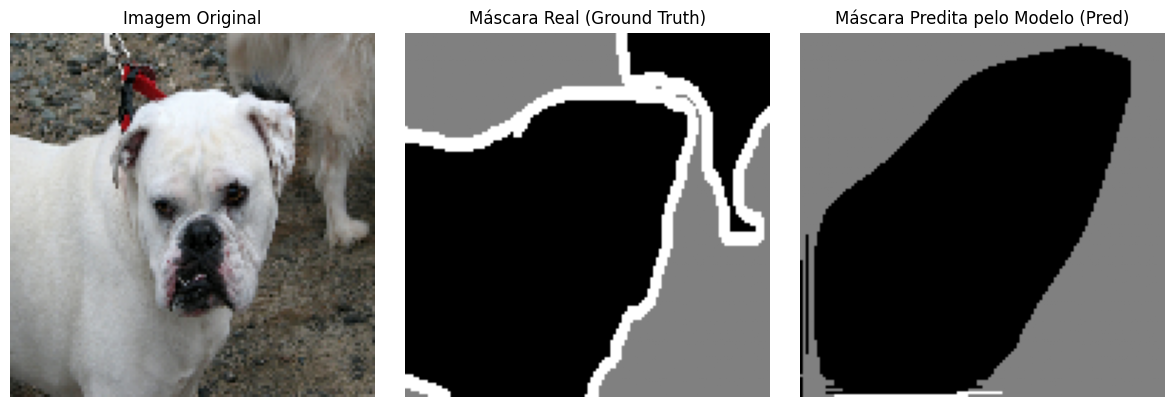

In [73]:
for images, masks in val_batches.take(1):
  img_exemplo = images[0]
  mask_real = masks[0]

  img_input = tf.expand_dims(img_exemplo, axis=0)

  preds_logits = model2.predict(img_input)

  pred_mask = tf.math.argmax(preds_logits[0], axis=-1)

  plt.figure(figsize=(12, 4))

# Imagem Original
plt.subplot(1, 3, 1)
plt.title("Imagem Original")
plt.imshow(img_exemplo / 255.0)
plt.axis("off")

# Máscara Real (Ground Truth)
plt.subplot(1, 3, 2)
plt.title("Máscara Real (Ground Truth)")
plt.imshow(mask_real[:, :, 0], cmap="gray")
plt.axis("off")

# Máscara Predita pelo Modelo
plt.subplot(1, 3, 3)
plt.title("Máscara Predita pelo Modelo (Pred)")
plt.imshow(pred_mask, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

# Aplicando Fine-Tuning

In [74]:
base_model.trainable = True

model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[foreground_iou]
)

history = model2.fit(
    train_batches,
    validation_data=val_batches,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 105s 315ms/step - foreground_iou: 0.6974 - loss: 0.4467 - val_foreground_iou: 0.7327 - val_loss: 0.4004
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 213ms/step - foreground_iou: 0.7645 - loss: 0.3467 - val_foreground_iou: 0.7595 - val_loss: 0.3684
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 214ms/step - foreground_iou: 0.7917 - loss: 0.3054 - val_foreground_iou: 0.7720 - val_loss: 0.3463
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 261ms/step - foreground_iou: 0.8066 - loss: 0.2810 - val_foreground_iou: 0.7780 - val_loss: 0.3376
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 196ms/step - foreground_iou: 0.8173 - loss: 0.2635 - val_foreground_iou: 0.7836 - val_loss: 0.3419
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 278ms/step - foreground_iou: 0.8271 - loss: 0.2479 - val_foreground_iou: 0.7924 - val_loss: 0.3232
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 267ms/step - foreground_iou: 0.8353 - loss: 0.2341 - val_foreground_iou: 0.7907 - val_loss: 0.3230
Epoch 8/10
9

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step


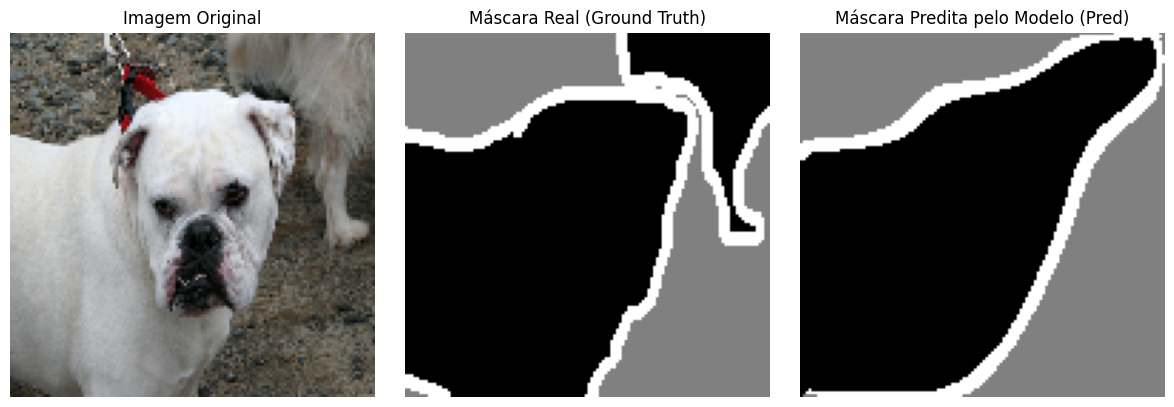

In [75]:
for images, masks in val_batches.take(1):
  img_exemplo = images[0]
  mask_real = masks[0]

  img_input = tf.expand_dims(img_exemplo, axis=0)

  preds_logits = model2.predict(img_input)

  pred_mask = tf.math.argmax(preds_logits[0], axis=-1)

  plt.figure(figsize=(12, 4))

# Imagem Original
plt.subplot(1, 3, 1)
plt.title("Imagem Original")
plt.imshow(img_exemplo / 255.0)
plt.axis("off")

# Máscara Real (Ground Truth)
plt.subplot(1, 3, 2)
plt.title("Máscara Real (Ground Truth)")
plt.imshow(mask_real[:, :, 0], cmap="gray")
plt.axis("off")

# Máscara Predita pelo Modelo
plt.subplot(1, 3, 3)
plt.title("Máscara Predita pelo Modelo (Pred)")
plt.imshow(pred_mask, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()